In [ ]:
from kalman import kalman_filter_main
import numpy as np

# x_est_prev is the current estimate of the state (X, Y, theta)
x_est_prev = np.array([[0],[0],[3]])
# P_est_prev is the covariance matrix of the current state
P_est_prev = [1000*np.ones(3)]
# vl_raw is the raw left motor speed directly from the thymio
vl_raw = 100
# vr_raw is the raw right motor speed directly from the thymio
vr_raw = 100
# robot_pose_cam is the camera pose (X, Y, theta)
robot_pose_cam = np.array([[0],[0],[3]])
# detection_valid is a boolean showing whether the camera can see the thymio
detection_valid = True

def kalman_call(x_est_prev, P_est_prev, vl_raw, vr_raw, robot_pose_cam, detection_valid):
    x_est, P_est = kalman_filter_main(x_est_prev, P_est_prev, vl_raw, vr_raw, robot_pose_cam, detection_valid)
    return x_est, P_est

x_est, P_est = kalman_call(x_est_prev, P_est_prev, vl_raw, vr_raw, robot_pose_cam, detection_valid)


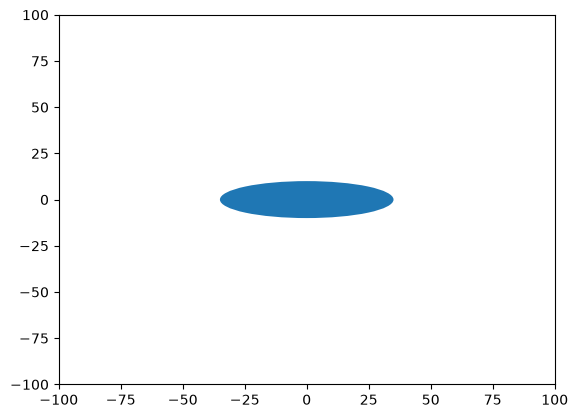

In [9]:
from numpy.linalg import eig
import numpy as np
import matplotlib.patches as mpatches
import matplotlib.pyplot as plt

# --- uncertainty ellipse ---
def plot_vcov_ellipse(P_est):
    sigma_x2 = P_est[0, 0]
    sigma_y2 = P_est[1, 1]
    ellipse_x_y = np.array([[sigma_x2, 0], [0, sigma_y2]])

    w,v=eig(ellipse_x_y)
    theta = np.arctan2(v[1,1], v[0,1])
    ellipse = mpatches.Ellipse(xy=(0,0), width=w[0], height=w[1], angle=np.degrees(theta))

    fig, ax = plt.subplots()
    ax.add_patch(ellipse)
    ax.set_xlim(-100, 100)
    ax.set_ylim(-100, 100)

    plt.show()

P_est = np.array([[20, 0, 0], [0, 70, 0], [0, 0, 10]])
plot_vcov_ellipse(P_est)
